# Lab 4: Working with 'Real' Data

    Saraliba Auch
    10/28/2026

## Introduction

In this lab we are going to work on how to estimate the background from 'real' data. Real is in air quotes because the data is actually from simplified simulations to make the problems manageable in a single lab. But the data will have some features that resemble that of real data sets.

## Getting data and HD5

In general exchanging raw data is a pain. Writing data in text files is error prone, inaccurate, and wastes space, but raw binary files have all sorts of subtleties too (including the internal byte order of your processor). To try and sidestep a whole set of nasty issues, we are going to use HDF5 (originally developed by the National Center for Supercomputing Applications for data exchange) to allow everyone to import the data. HDF5 has become a prefered way for projects to save and exchange data.

You will need to install the h5py library. At the top of your notebook you should then have an import that looks like:

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

import astropy
from astropy import units as u
from astropy import constants as const
from astropy.time import Time
from astropy.units import imperial
from astropy.table import QTable

UW IT has nicely setup a new folder on your JupyterHub machine that contains the large data file we will need for this lab. If you look in the terminal you should see a new folder in your home directory called Shared, in which there will be a file called gammaray_lab4.h5.

Now open the file as a read-only file ('r' means read only, the path for this example command assumes the Shared directory is beside your git code directory the exact path depends on your file structure.)

In [2]:
hf = h5py.File('gammaray_lab4.h5', 'r')

Within hdf5 files you can store different kinds of data sets. Ours is simple and has only one table of data called 'data'. You can look at the header and see this using

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

You can then import the data into an array variable using the get method (this may take a few moments)

In [4]:
data = np.array(hf.get('data'))
data = np.transpose(data)

Check that your data is as expected, with a time (in gps seconds), Solar phase (deg), Earth longitude (deg), and gamma-ray counts, and more than 25 million data records.


In [5]:
print(np.shape(data))
print(data[:,0])

(25920001, 4)
[9.40680016e+08 9.40680016e+08 9.40680016e+08 ... 9.43272016e+08
 9.43272016e+08 9.43272016e+08]


The above commands will give you the dimensions of the array, and print the values in the first row.

You can then close your file (the data has been read into the memory array data)

In [6]:
hf.close()

In [7]:
#Organizes the data into a table
col_name = ['Time','Solar Phase','Earth Longitude','Gamma-Ray Count']

data = QTable(data,
              names = col_name)

data['Time'].unit = u.s
data['Solar Phase'].unit = u.deg
data['Earth Longitude'].unit = u.deg
data['Gamma-Ray Count'].unit = u.dimensionless_unscaled

In [8]:
def slice_plot(data, col_1, col_2, start_val, quantity, step=1):
    '''
    Creates a scatter plot for the desired data over a specified quantity
    data is the data table you want the data from
    col_1 and col_2 are the x and y values respectively
    start val is what value you want to start with (It is 1+the index)
    quantity is how many data points you want to plot
    '''
    fig, axes = plt.subplots(figsize=(15,5))
    
    axes.scatter(data[col_1][start_val-1: start_val+quantity: step], 
                 data[col_2][start_val-1: start_val+quantity: step])
    axes.grid(alpha=0.3)
    plt.xlabel(col_1)
    plt.ylabel(col_2)


def slice_2dhist(data, col_1, col_2, start_val, quantity, step=1):    
    '''
    Creates a 2d histogram for the desired data over a specified quantity
    data is the data table you want the data from
    col_1 and col_2 are the x and y values respectively
    start val is what value you want to start with (It is 1+the index)
    quantity is how many data points you want to plot
    '''
    x_val = data[col_1][start_val-1: start_val+quantity: step].value
    y_val = data[col_2][start_val-1: start_val+quantity: step].value
    
    fig, ax = plt.subplots(1,1)
    hist = ax.hist2d(x_val, y_val,
                     cmap = 'magma',
                     bins= [np.arange(np.min(x_val),np.max(x_val)),np.arange(np.min(y_val),np.max(y_val))],
                     density=True)
    plt.xlabel(col_1)
    plt.ylabel(col_2)
    plt.colorbar(hist[3], ax=ax, shrink=.90)

## Problem

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

**1. Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().**

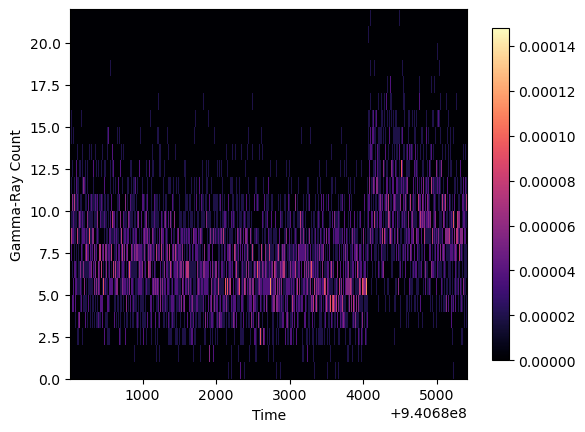

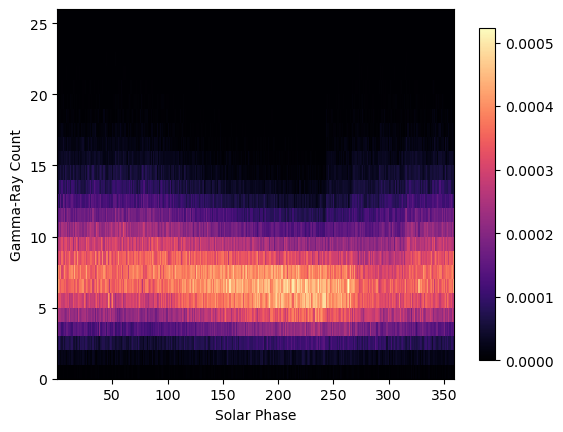

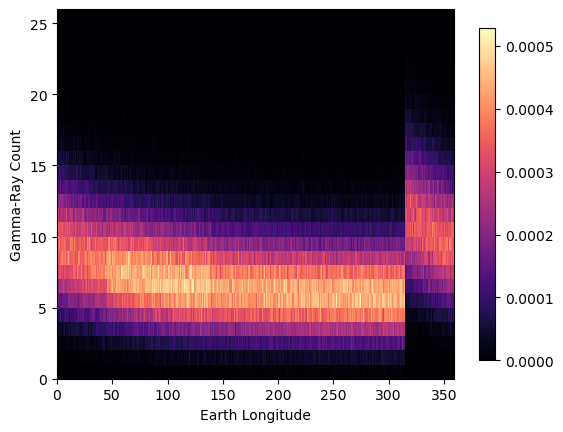

In [9]:
#Visual analysis of the data

#This shows how the gamma-ray count varies over 1 complete orbit
slice_2dhist(data, 'Time','Gamma-Ray Count', 1,54000)
#how the gamma-ray count changes as the solar phase changes over 1 complete orbit
slice_2dhist(data, 'Solar Phase', 'Gamma-Ray Count', 1,500000)
#how the gamma-ray count changes as the Earth longitude changes over 1 complete orbit
slice_2dhist(data,'Earth Longitude','Gamma-Ray Count', 1,500000)

    Gamma-Ray Counts:
    The is a discrete value, so it follows a Poisson distribution. The histogram displays one complete orbit, or 54,000 data points(1 image every 100 milliseconds, with an orbit of 90 minutes). There is a weird spike on the right end of the data, that slowly tapers off. 
    
    Solar Phase:
    The solar phase does not seem to seem to effect the counts too much, as their is little fluncuation. The histogram for the solar phase includes roughly nine orbits. 

    Earth Longitude:
    The counts for Earth longitude is also for 9 orbits. There seems to be a consistant signal jump aroun 320 degrees, meaning there is likly a signal contamination coming from that spot on the Earth. 

    Background:
    The "Gamma-Ray Counts" is actually mostly cosmic rays from the background. The distribution of this background will be a Poisson because it is discrete. The background would have to account for the spike caused by the satellite's position relative to the Earth. Therefore as time varies, and the satellite orbits around the Earth, the background distribution will change
    

**2. The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.**

In [10]:
def loc_gamma_subset(start_pos, end_pos):
    '''
    Creates a table with just the Gamma-Ray Counts that happen between two longitudnal lines
    '''
    loc_subset = data[(data['Earth Longitude'].value >= start_pos) &
                  (data['Earth Longitude'].value <= end_pos)]
    result = loc_subset['Gamma-Ray Count']
    return result

def num_bins(start_pos,end_pos):
    '''
    Calculates the optimal number of bins by finding the maximum number of counts from given data subset
    This function ends up not working because I didn't the result is not an integer. 
    I didn't find that out until later, so I just used this function to hardcode the number of bins
    in my histograms for this question
    '''
    result = np.max(loc_gamma_subset(start_pos, end_pos))
    return result

In [11]:
#me getting the values to use below
max_1 = num_bins(0,60)
max_2 = num_bins(60,120)
max_3 = num_bins(120,180)
max_4 = num_bins(180,240)
max_5 = num_bins(240,300)
max_6 = num_bins(300,360)

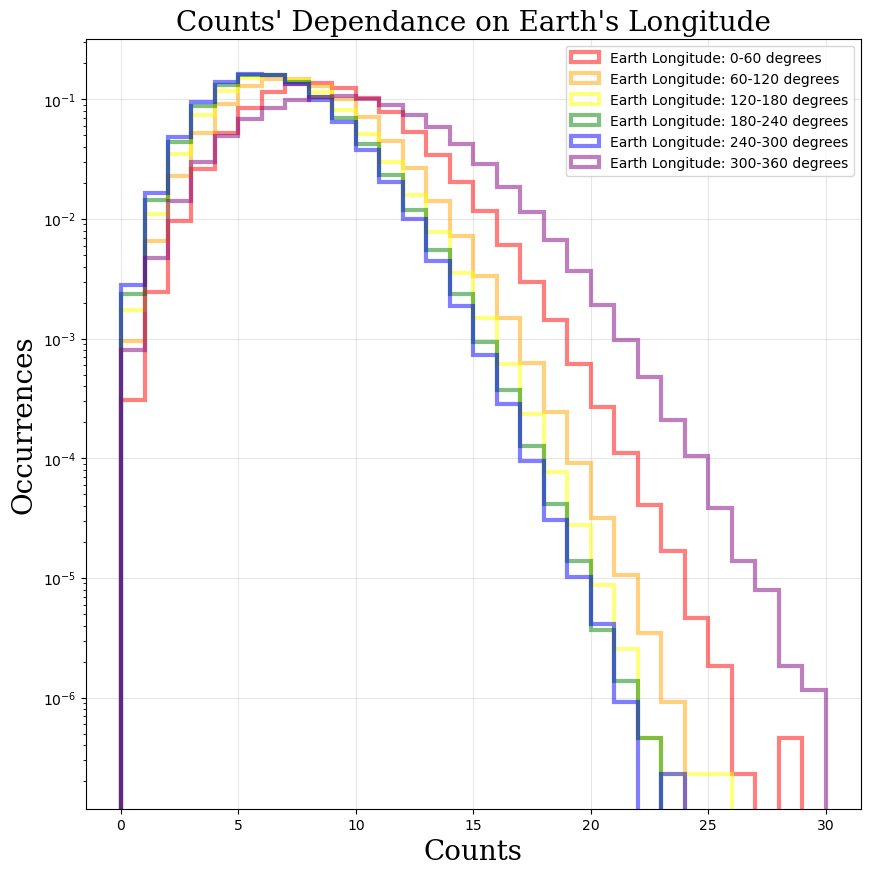

In [12]:
#plots how the background distribution changes as the satellite's position over Earth changes. 
#There are six plots, and each plot covers 60 degrees

fig, ax = plt.subplots(figsize=(10, 10))

ax.hist(loc_gamma_subset(0,60),
       histtype='step',
        bins=29,
       label = r'Earth Longitude: 0-60 degrees',
       color = 'red',
       linewidth = 3,
       alpha = .5,
       density = True)
ax.hist(loc_gamma_subset(60,120),
        histtype='step',
        bins=24,
        label = r'Earth Longitude: 60-120 degrees',
       color = 'orange',
       linewidth = 3,
       alpha = .5,
       density = True)
ax.hist(loc_gamma_subset(120,180),
        histtype='step',
        bins=26,
        label = r'Earth Longitude: 120-180 degrees',
       color = 'yellow',
       linewidth = 3,
       alpha = .5,
       density = True)
ax.hist(loc_gamma_subset(180,240),
        histtype='step',
        bins=23,
        label = r'Earth Longitude: 180-240 degrees',
       color='green',
       linewidth = 3,
       alpha = .5,
       density = True)
ax.hist(loc_gamma_subset(240,300),
        histtype='step',
        bins=24,
        label = r'Earth Longitude: 240-300 degrees',
       color='blue',
       linewidth = 3,
       alpha = .5,
       density = True)
ax.hist(loc_gamma_subset(300,360),
        histtype='step',
        bins=30,
        label = r'Earth Longitude: 300-360 degrees',
       color='purple',
       linewidth = 3,
       alpha = .5,
       density = True)

ax.set_yscale('log')
ax.set_xlabel("Counts",
              fontfamily = 'serif',
              fontsize = 20)

ax.set_ylabel("Occurrences",
              fontfamily = 'serif',
              fontsize = 20)

ax.set_title("Counts' Dependance on Earth's Longitude",
             fontfamily = 'serif',
             fontsize = 20)
ax.legend()
ax.grid(alpha=0.3)
#axes.set_xlabel("Gamma-Ray Count")
#axes.set_ylabel('Occurances')

    The graph above follows what I would expect from the histograms I created above.
    Earth Longitude: 0-180 degrees
        The mean stays fairly consistance, but the spread of the counts gradually decreases as longitude increases. 
    Earth Longitude: 180-300
        The distribution remains faily consistant from 180-300 degreed. This is reflected in the histograms is question one as the number of counts between 150-300 degrees appeared fairly steady. 
    Earth Longidude: 300-360
        This distribution appears to have a larger mean and is much more spread out than the other distributions. This is what I would expect, since the number of counts spike shortly after passing 300 degrees longitude.

**3. Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?**

In [13]:
#This block of code will define the background model

#all of the time values
time = data['Time'].value
#how many data points make up one orbit
orbit = 54000

#this fold all of the data for time of one orbit
fold_time = time % orbit
#adds the folded data to the original data table
data['Folded Time'] = fold_time

#Creats a data subset of Gamma-Ray Counts depending on how many orbits have been completed
def time_subset(num_orbit):
    #converts the number of orbits to seconds to it can be related to the folded time values
    orbit_time = num_orbit * orbit
    phase = orbit_time % orbit
    #need a range of time to find times to create a subset
    #the subset is 6 seconds before and after the given time
    min_phs = phase-60
    max_phs = phase+60

    #removes the data that do not fall within the given time
    time_subset = data[(data['Folded Time'].value >= min_phs) &
                  (data['Folded Time'].value <= max_phs)]
    #takes just the Gamma-Ray Counts from the reduced data
    result = time_subset['Gamma-Ray Count']
    return result

#This is the model pmf, based on the num-orbits(time)
def pmf(num_orbit):  
    #finds the mean of the time subset. Through trial and error, I found increases the mean by one produces the best result
    mean = np.mean(time_subset(num_orbit))+1
    #create the Poisson pmf
    dist = np.arange(0,30)
    result = stats.poisson.pmf(dist, mean)
    return result

#This finds the optimal number of bins for my histogram
def num_bins(num_orbit):
    #bins have to be an interger. The number of bins is just the max value of the time subset
    result = int(np.max(np.max(time_subset(num_orbit))))
    return result

Text(0.5, 1.0, 'Count Dependence on Orbit')

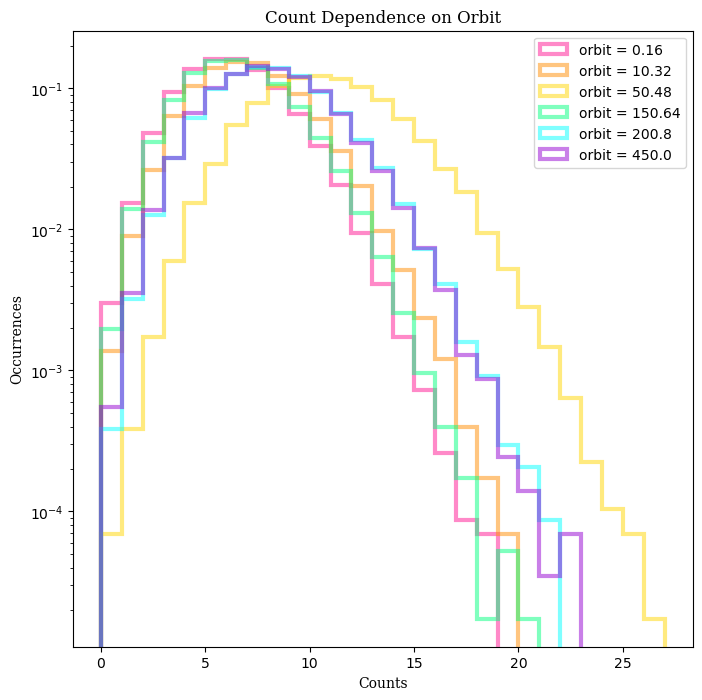

In [14]:
#Plots how the background distribution changes as it is in different parts of its orbit
#There are 6 plots that vary from 0-480, the decimal part of each orbit value increase by 0.16
#This shows that my model works across time and at different part of the orbit
#orbit zero does not correspond to zero longitude, so different colors are used than above so there is not confusion

fig, ax = plt.subplots(figsize=(8,8))

value = 0.16
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'deeppink',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')

value=10.32
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'darkorange',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')

value=50.48
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'gold',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')

value=150.64
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'springgreen',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')

value=200.80
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'cyan',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')

value=450.0
ax.hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'darkviolet',
       linewidth = 3,
       alpha = .5,
       density = True,
       label = f'orbit = {value}')


ax.set_yscale('log')
ax.legend()
ax.set_xlabel("Counts",fontfamily = 'serif')
ax.set_ylabel("Occurrences",fontfamily = 'serif')
ax.set_title('Count Dependence on Orbit',fontfamily='serif')

Text(0.5, 0, 'Counts')

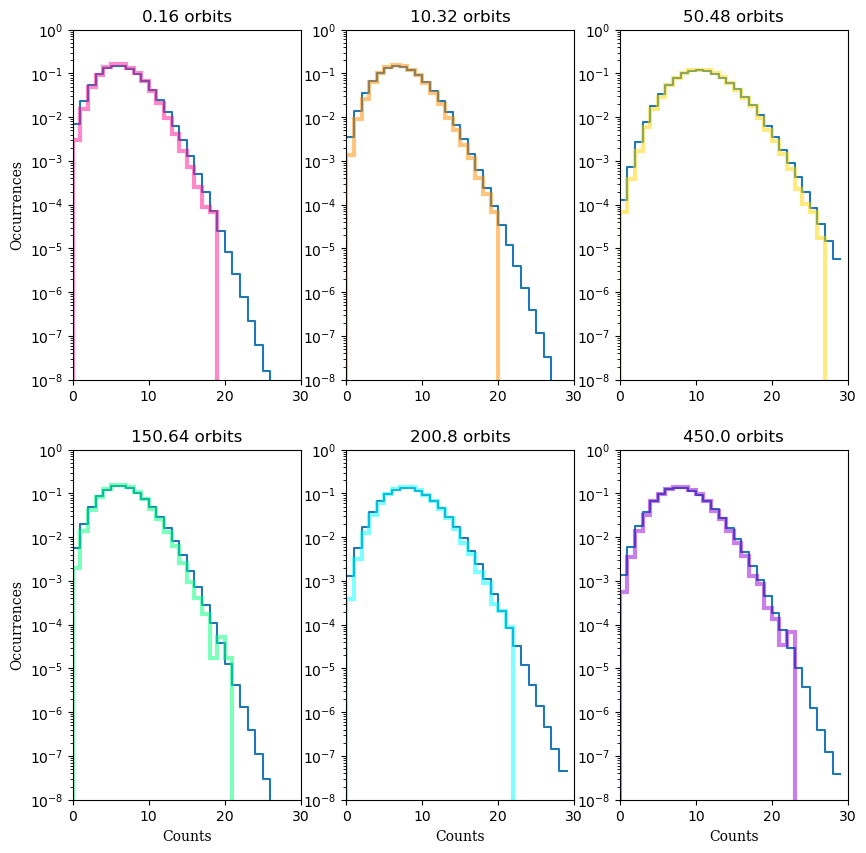

In [15]:
#Applies my model to the above distributions
#The blue line is the model
#The colors above apply to the same colors below

fig, ax = plt.subplot_mosaic(
    '''
    ABC
    DEF
    ''',
    figsize=(10, 10))

value = 0.16
ax['A'].step(np.arange(0,30),pmf(value))
ax['A'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'deeppink',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['A'].set_title(f'{value} orbits')

value=10.32
ax['B'].step(np.arange(0,30),pmf(value))
ax['B'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'darkorange',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['B'].set_title(f'{value} orbits')

value=50.48
ax['C'].step(np.arange(0,30), 
        pmf(value))
ax['C'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'gold',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['C'].set_title(f'{value} orbits')

value=150.64
ax['D'].step(np.arange(0,30), 
        pmf(value))
ax['D'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'springgreen',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['D'].set_title(f'{value} orbits')

value=200.80
ax['E'].step(np.arange(0,30), 
        pmf(value))
ax['E'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'cyan',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['E'].set_title(f'{value} orbits')

value=450.0
ax['F'].step(np.arange(0,30), 
        pmf(value))
ax['F'].hist(time_subset(value),
       histtype='step',
        bins=num_bins(value),
       color = 'darkviolet',
       linewidth = 3,
       alpha = .5,
       density = True)
ax['F'].set_title(f'{value} orbits')

ax['A'].set_yscale('log')
ax['B'].set_yscale('log')
ax['C'].set_yscale('log')
ax['D'].set_yscale('log')
ax['E'].set_yscale('log')
ax['F'].set_yscale('log')

ax['A'].set_xlim(0,30)
ax['B'].set_xlim(0,30)
ax['C'].set_xlim(0,30)
ax['D'].set_xlim(0,30)
ax['E'].set_xlim(0,30)
ax['F'].set_xlim(0,30)

ax['A'].set_ylim(10**(-8),1)
ax['B'].set_ylim(10**(-8),1)
ax['C'].set_ylim(10**(-8),1)
ax['D'].set_ylim(10**(-8),1)
ax['E'].set_ylim(10**(-8),1)
ax['F'].set_ylim(10**(-8),1)

ax['A'].set_ylabel("Occurrences",fontfamily = 'serif')
ax['D'].set_xlabel("Counts",fontfamily = 'serif')
ax['D'].set_ylabel("Occurrences",fontfamily = 'serif')
ax['E'].set_xlabel("Counts",fontfamily = 'serif')
ax['F'].set_xlabel("Counts",fontfamily = 'serif')

    The model appears to fit the values very well. Is curious that none of the distributions based on the data have a very low probability of counts. Expecially because there are over 2 million data points. Prehaps we would see a fuller distribution if there were 2 million data points for each of my time ranges. 

**4. Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?**

In [16]:
five_sigma_prob = stats.norm.sf(5)

orbit_values = [0.16,10.32,50.48,150.64,200.8,450.0]

for x in orbit_values:
    count = stats.poisson.isf(five_sigma_prob, mu =np.mean(time_subset(x))+1)
    print(f'a 5 sigma event for {x} orbits is {int(count)}')

a 5 sigma event for 0.16 orbits is 24
a 5 sigma event for 10.32 orbits is 25
a 5 sigma event for 50.48 orbits is 32
a 5 sigma event for 150.64 orbits is 24
a 5 sigma event for 200.8 orbits is 27
a 5 sigma event for 450.0 orbits is 27


**5. While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?**

    My guess is the signal contamination occures when the satalite is passing over the South Atlantic, because of the South Atlantic Anomaly. The Van Allen radiation belt comes closest to the Earth's surface in that area, which causes a heave bombarment of cosmic rays.